In [30]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
df = pd.read_csv("foodhub_order.csv")

In [32]:
df

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24
...,...,...,...,...,...,...,...,...,...
1893,1476701,292602,Chipotle Mexican Grill $1.99 Delivery,Mexican,22.31,Weekend,5,31,17
1894,1477421,397537,The Smile,American,12.18,Weekend,5,31,19
1895,1477819,35309,Blue Ribbon Sushi,Japanese,25.22,Weekday,Not given,31,24
1896,1477513,64151,Jack's Wife Freda,Mediterranean,12.18,Weekday,5,23,31


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


In [34]:
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


In [35]:
df.tail()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
1893,1476701,292602,Chipotle Mexican Grill $1.99 Delivery,Mexican,22.31,Weekend,5,31,17
1894,1477421,397537,The Smile,American,12.18,Weekend,5,31,19
1895,1477819,35309,Blue Ribbon Sushi,Japanese,25.22,Weekday,Not given,31,24
1896,1477513,64151,Jack's Wife Freda,Mediterranean,12.18,Weekday,5,23,31
1897,1478056,120353,Blue Ribbon Sushi,Japanese,19.45,Weekend,Not given,28,24


In [36]:
df.shape

(1898, 9)

In [37]:
df.isnull().sum()

order_id                 0
customer_id              0
restaurant_name          0
cuisine_type             0
cost_of_the_order        0
day_of_the_week          0
rating                   0
food_preparation_time    0
delivery_time            0
dtype: int64

In [38]:
df.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


In [39]:
df.nunique()

order_id                 1898
customer_id              1200
restaurant_name           178
cuisine_type               14
cost_of_the_order         312
day_of_the_week             2
rating                      4
food_preparation_time      16
delivery_time              19
dtype: int64

In [40]:
df.sort_values(by='cost_of_the_order',ascending=False)

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
573,1477814,62359,Pylos,Mediterranean,35.41,Weekday,4,21,29
1646,1477665,231061,Han Dynasty,Chinese,34.19,Weekday,Not given,21,31
1762,1477700,60039,Blue Ribbon Sushi,Japanese,33.37,Weekday,3,30,27
1831,1476970,275689,Nobu Next Door,Japanese,33.37,Weekend,4,32,21
1370,1478329,116992,Tres Carnes,Mexican,33.32,Weekday,4,21,33
...,...,...,...,...,...,...,...,...,...
82,1477790,133617,Shake Shack,American,4.75,Weekday,4,35,28
1569,1477786,145389,RedFarm Hudson,Chinese,4.75,Weekend,3,23,25
542,1477788,270444,P.J. Clarke's,American,4.71,Weekend,Not given,23,15
480,1476877,53289,The Loop,Japanese,4.66,Weekend,Not given,34,25


In [41]:
df['food_preparation_time'].min()

20

In [42]:
(df['rating'] == 'Not given').sum()

np.int64(736)

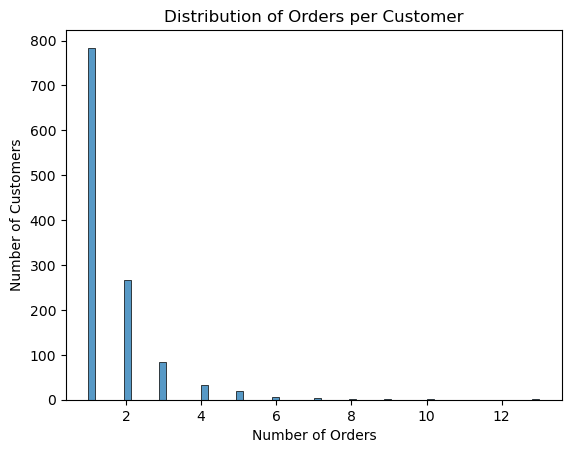

In [43]:
order_counts = df['customer_id'].value_counts()

sns.histplot(order_counts)  
plt.title('Distribution of Orders per Customer')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')
plt.show()

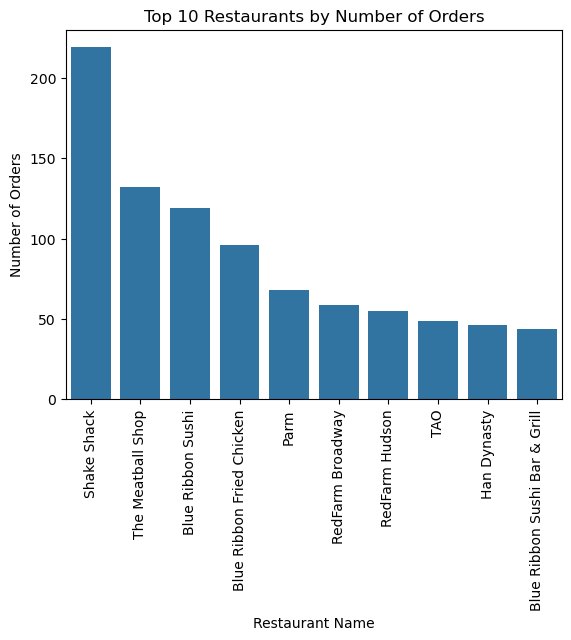

In [44]:
top_restaurants = df['restaurant_name'].value_counts().head(10)

sns.barplot(x=top_restaurants.index, y=top_restaurants.values)
plt.title('Top 10 Restaurants by Number of Orders')
plt.xlabel('Restaurant Name')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)
plt.show()

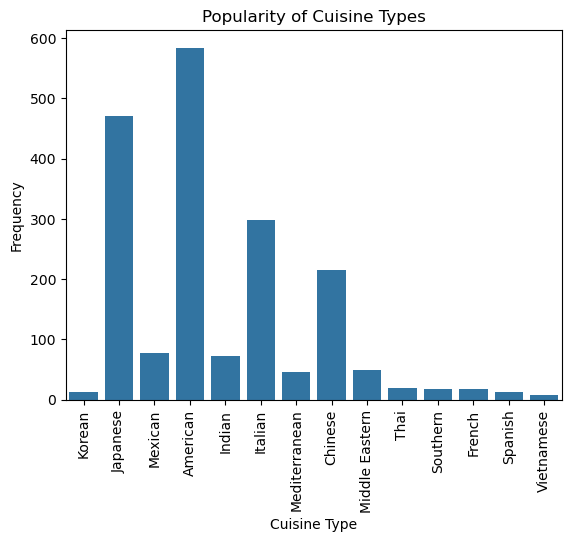

In [45]:
sns.countplot(x=df['cuisine_type'])
plt.title('Popularity of Cuisine Types')
plt.xlabel('Cuisine Type')
plt.ylabel('Frequency')
plt.xticks(rotation=90)
plt.show()

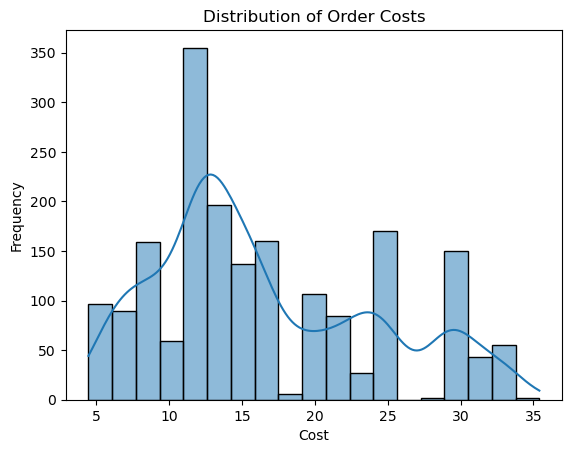

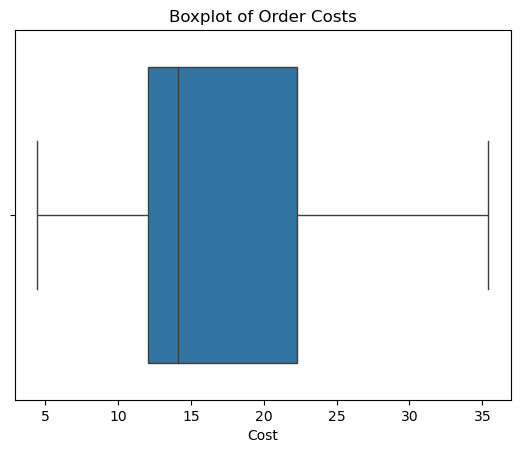

In [46]:
sns.histplot(df['cost_of_the_order'], kde=True)
plt.title('Distribution of Order Costs')
plt.xlabel('Cost')
plt.ylabel('Frequency')
plt.show()
print('\n')
sns.boxplot(x=df['cost_of_the_order'])
plt.title('Boxplot of Order Costs')
plt.xlabel('Cost')
plt.show()

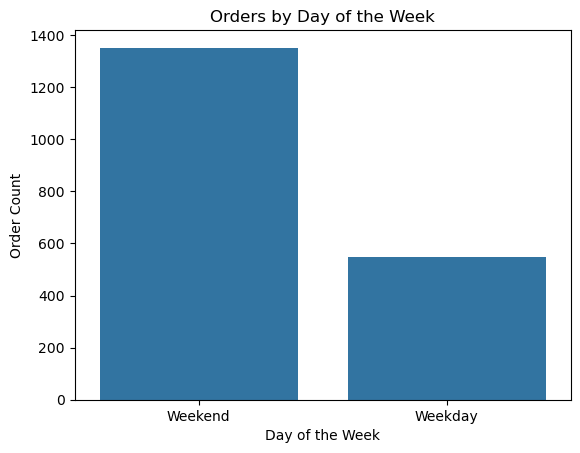

In [47]:
sns.countplot(x=df['day_of_the_week'])
plt.title('Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Order Count')
plt.show()

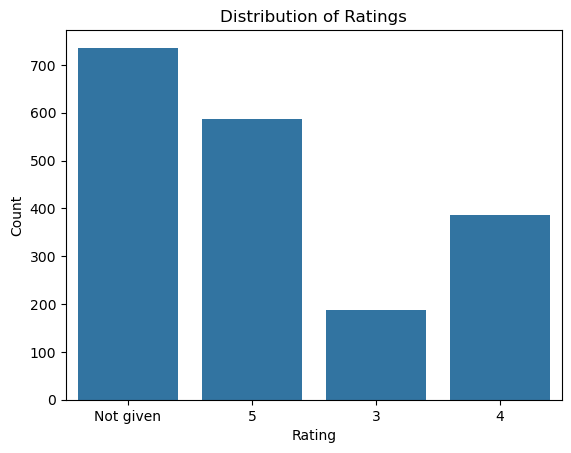

In [48]:
sns.countplot(x=df['rating'])
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

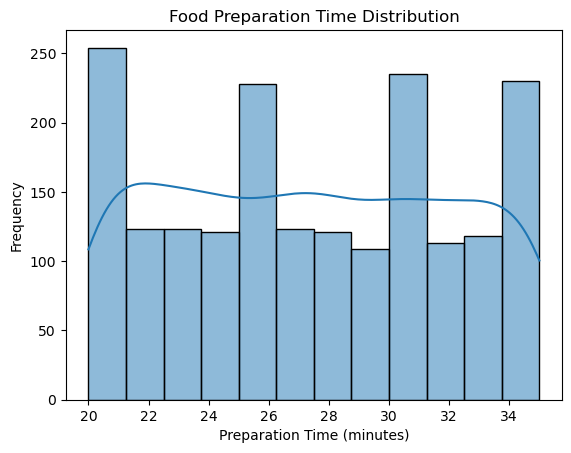

In [49]:
sns.histplot(df['food_preparation_time'], kde=True)
plt.title('Food Preparation Time Distribution')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Frequency')
plt.show()

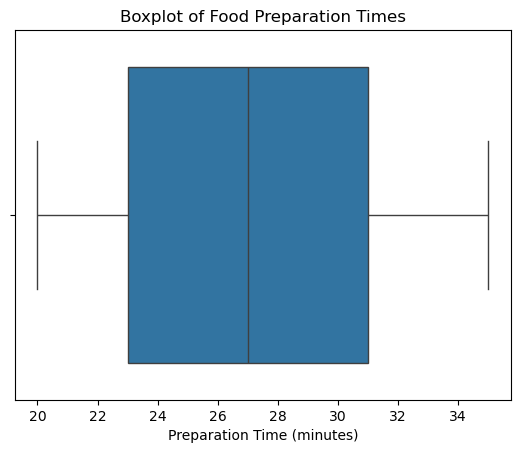

In [50]:
sns.boxplot(x=df['food_preparation_time'])
plt.title('Boxplot of Food Preparation Times')
plt.xlabel('Preparation Time (minutes)')
plt.show()

In [51]:
top_5_restaurants = df['restaurant_name'].value_counts().head(5)
print("Top 5 restaurants by number of orders:")
print(top_5_restaurants)

Top 5 restaurants by number of orders:
restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
Name: count, dtype: int64


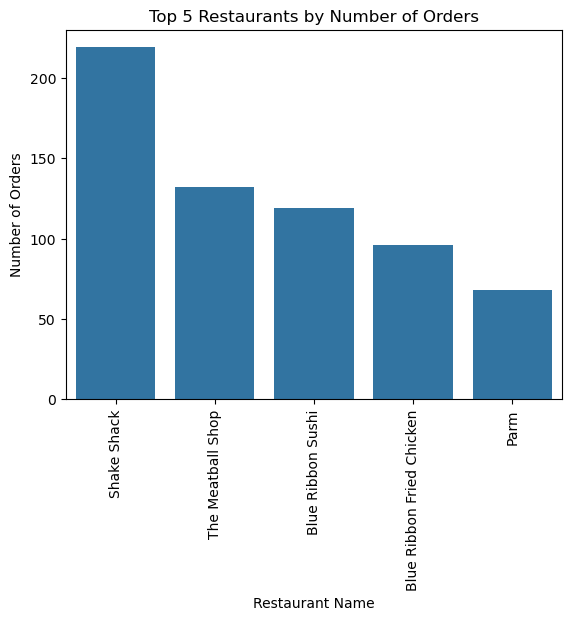

In [52]:
sns.barplot(x=top_5_restaurants.index, y=top_5_restaurants.values)
plt.title('Top 5 Restaurants by Number of Orders')
plt.xlabel('Restaurant Name')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)  
plt.show()

In [53]:
df['day_of_the_week'] == 'Weekend'

0        True
1        True
2       False
3        True
4       False
        ...  
1893     True
1894     True
1895    False
1896    False
1897     True
Name: day_of_the_week, Length: 1898, dtype: bool

In [54]:
(df.cuisine_type.value_counts()).idxmax()

'American'

In [55]:
Weekend=df[df['day_of_the_week'] == 'Weekend']

In [58]:
Weekend

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
6,1477894,157711,The Meatball Shop,Italian,6.07,Weekend,Not given,28,21
11,1478437,221206,Empanada Mama (closed),Mexican,8.10,Weekend,5,23,22
...,...,...,...,...,...,...,...,...,...
1891,1476981,138586,Shake Shack,American,5.82,Weekend,Not given,22,28
1892,1477473,97838,Han Dynasty,Chinese,29.15,Weekend,Not given,29,21
1893,1476701,292602,Chipotle Mexican Grill $1.99 Delivery,Mexican,22.31,Weekend,5,31,17
1894,1477421,397537,The Smile,American,12.18,Weekend,5,31,19


In [57]:
popular_cuisine_weekend = Weekend['cuisine_type'].value_counts()
most_popular_cuisine = popular_cuisine_weekend.idxmax()
print(f"The most popular cuisine on weekends is: {most_popular_cuisine}")

The most popular cuisine on weekends is: American


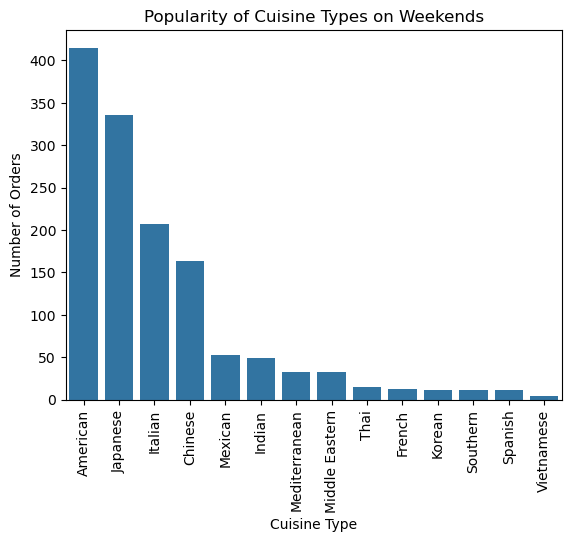

In [59]:
sns.barplot(x=popular_cuisine_weekend.index, y=popular_cuisine_weekend.values)
plt.title('Popularity of Cuisine Types on Weekends')
plt.xlabel('Cuisine Type')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)  
plt.show()

In [63]:
orders_above_20 = df[df['cost_of_the_order'] > 20]
count_orders_above_20 = orders_above_20.shape[0]
total_orders = df.shape[0]
percentage_above_20 = (count_orders_above_20 / total_orders) * 100
print(f"{percentage_above_20:.2f}%")

29.24%


In [62]:
mean_delivery_time = df['delivery_time'].mean()
print(f"{mean_delivery_time:.2f} minutes")


24.16 minutes


In [64]:
customer_order_counts = df['customer_id'].value_counts()
top_3_customers = customer_order_counts.head(3)
print(top_3_customers)

customer_id
52832    13
47440    10
83287     9
Name: count, dtype: int64


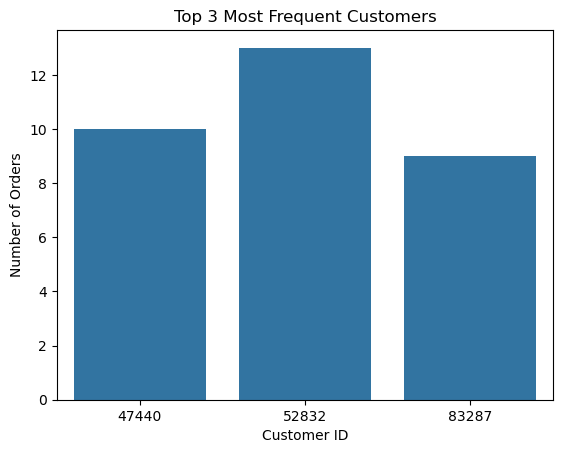

In [65]:
sns.barplot(x=top_3_customers.index, y=top_3_customers.values)
plt.title('Top 3 Most Frequent Customers')
plt.xlabel('Customer ID')
plt.ylabel('Number of Orders')
plt.show()

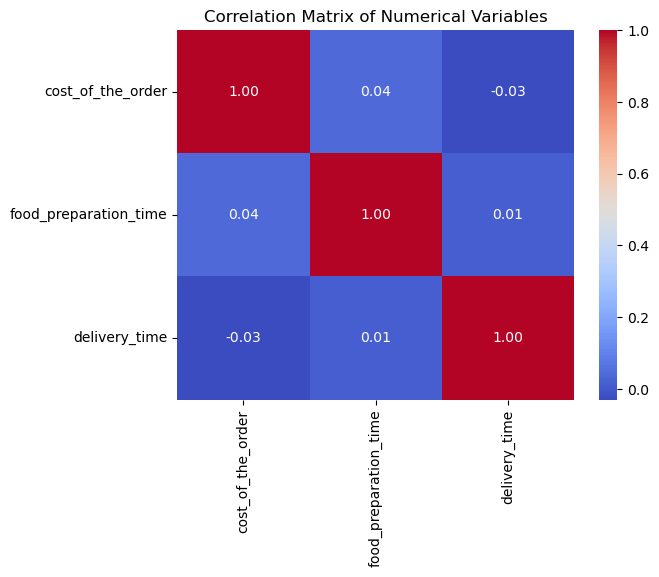

In [66]:
corr = df[['cost_of_the_order', 'food_preparation_time', 'delivery_time']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

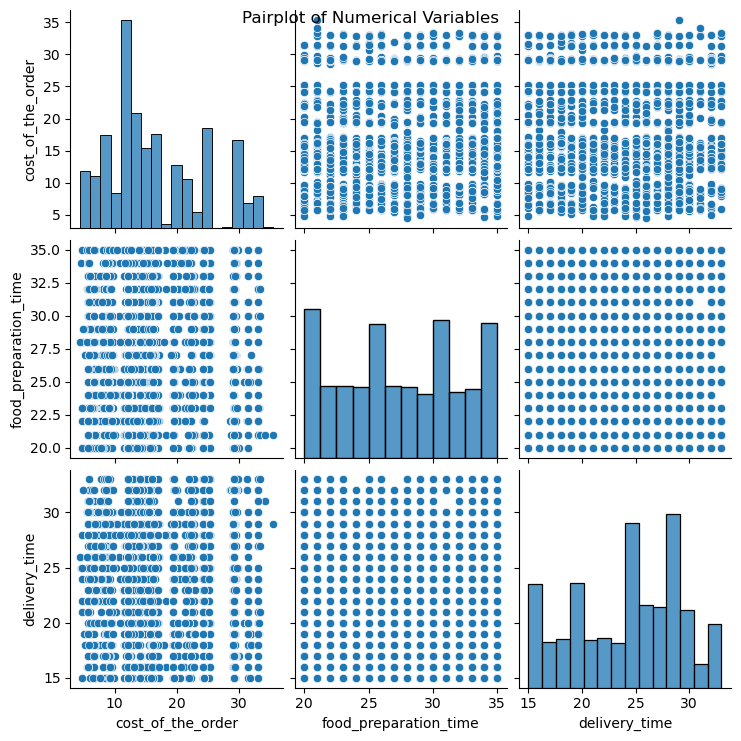

In [67]:
sns.pairplot(df[['cost_of_the_order', 'food_preparation_time', 'delivery_time']])
plt.suptitle('Pairplot of Numerical Variables', verticalalignment='top')
plt.show()

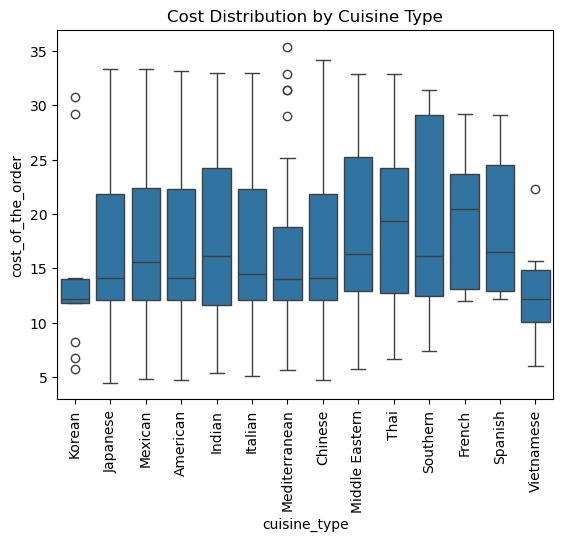

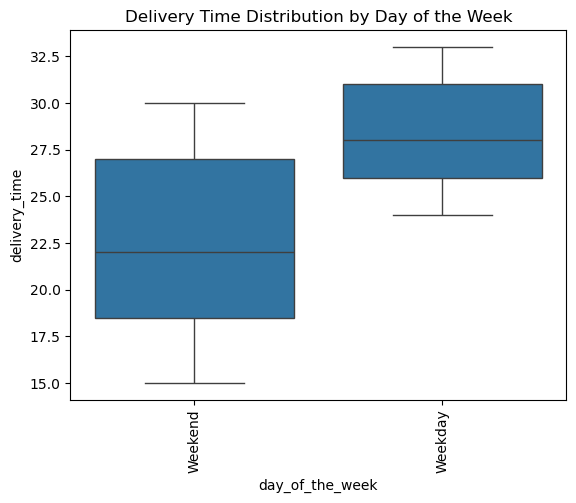

In [69]:
sns.boxplot(x='cuisine_type', y='cost_of_the_order', data=df)
plt.title('Cost Distribution by Cuisine Type')
plt.xticks(rotation=90)
plt.show()
print('\n')

sns.boxplot(x='day_of_the_week', y='delivery_time', data=df)
plt.title('Delivery Time Distribution by Day of the Week')
plt.xticks(rotation=90)
plt.show()

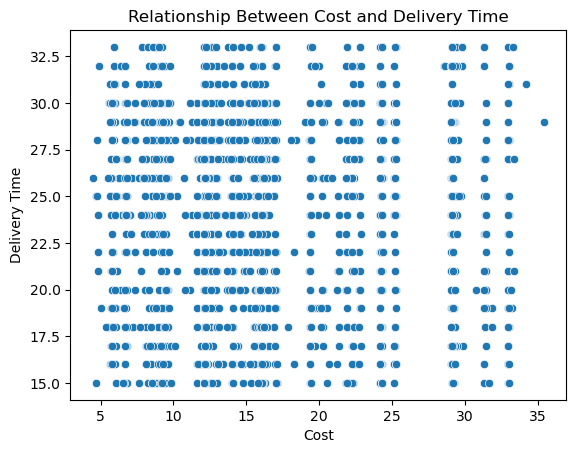

In [70]:
sns.scatterplot(x='cost_of_the_order', y='delivery_time', data=df)
plt.title('Relationship Between Cost and Delivery Time')
plt.xlabel('Cost')
plt.ylabel('Delivery Time')
plt.show()

In [71]:
df['rating'].replace('Not given', np.nan, inplace=True)
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
restaurant_ratings = df.groupby('restaurant_name')['rating'].agg(count='count', mean='mean')
eligible_restaurants = restaurant_ratings[(restaurant_ratings['count'] > 50) & (restaurant_ratings['mean'] > 4)]
print("Restaurants eligible for the promotional offer:")
print(eligible_restaurants)

Restaurants eligible for the promotional offer:
                           count      mean
restaurant_name                           
Blue Ribbon Fried Chicken     64  4.328125
Blue Ribbon Sushi             73  4.219178
Shake Shack                  133  4.278195
The Meatball Shop             84  4.511905


C:\Users\zee\AppData\Local\Temp\ipykernel_3504\1368495776.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['rating'].replace('Not given', np.nan, inplace=True)


In [74]:
def calculate_commission(cost):
    if cost > 20:
        return cost * 0.25
    elif cost > 5:
        return cost * 0.15
    else:
        return 0
df['commission'] = df['cost_of_the_order'].apply(calculate_commission)
total_revenue = df['commission'].sum()
print(f"${total_revenue:.2f}")


$6166.30


In [75]:
df['total_delivery_time'] = df['food_preparation_time'] + df['delivery_time']
orders_over_60 = df[df['total_delivery_time'] > 60].shape[0]
total_orders = df.shape[0]
percentage_over_60 = (orders_over_60 / total_orders) * 100
print(f"{percentage_over_60:.2f}%")


10.54%


In [76]:
mean_delivery_times = df.groupby('day_of_the_week')['delivery_time'].mean()
print(mean_delivery_times)

day_of_the_week
Weekday    28.340037
Weekend    22.470022
Name: delivery_time, dtype: float64


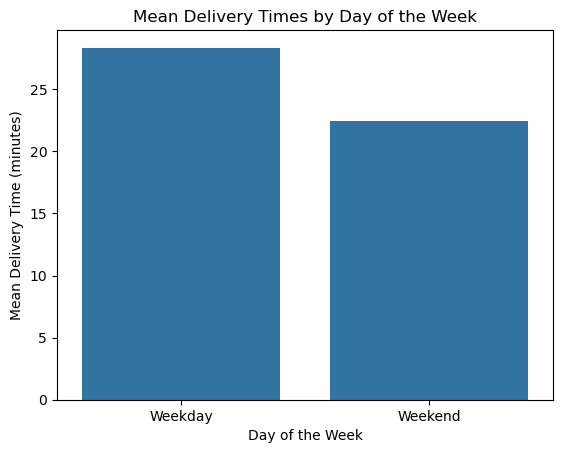

In [77]:
sns.barplot(x=mean_delivery_times.index, y=mean_delivery_times.values)
plt.title('Mean Delivery Times by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Mean Delivery Time (minutes)')
plt.show()